In [ ]:
from __future__ import print_function
from __future__ import division

import numpy as np
import pandas as pd

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as D
from torch.optim.lr_scheduler import ExponentialLR

import time
import os
import copy

import torchvision
from torchvision import models, transforms as T

import tensorflow as tf

from tqdm import tqdm_notebook
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')


import matplotlib.pyplot as plt

import cv2
from skimage.color import rgb2gray

from itertools import islice

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_dir = '/content/drive/My Drive/rxrx1'
model_name = "resnet" # Models to choose from [resnet, alexnet, vgg, squeezenet, densenet, inception]
num_classes = 1139
batch_size = 64
num_epochs = 25
# Flag for feature extracting. When False, we finetune the whole model,
#   when True we only update the reshaped layer params
feature_extract = True

In [ ]:
def set_parameter_requires_grad(model, feature_extracting):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

In [ ]:
def initialize_model(model_name, num_classes, feature_extract, use_pretrained=True):
    # Initialize these variables which will be set in this if statement. Each of these
    #   variables is model specific.
    model_ft = None
    input_size = 0

    if model_name == "resnet":
        """ Resnet18
        """
        model_ft = models.resnet18(pretrained=use_pretrained)
        set_parameter_requires_grad(model_ft, feature_extract)
        num_ftrs = model_ft.fc.in_features
        model_ft.fc = nn.Linear(num_ftrs, num_classes) #changing the last layer
        input_size = 224

    elif model_name == "alexnet":
        """ Alexnet
        """
        model_ft = models.alexnet(pretrained=use_pretrained)
        set_parameter_requires_grad(model_ft, feature_extract)
        num_ftrs = model_ft.classifier[6].in_features
        model_ft.classifier[6] = nn.Linear(num_ftrs,num_classes)
        input_size = 224

    elif model_name == "squeezenet":
        """ Squeezenet
        """
        model_ft = models.squeezenet1_0(pretrained=use_pretrained)
        set_parameter_requires_grad(model_ft, feature_extract)
        model_ft.classifier[1] = nn.Conv2d(512, num_classes, kernel_size=(1,1), stride=(1,1))
        model_ft.num_classes = num_classes
        input_size = 224

    elif model_name == "densenet":
        """ Densenet
        """
        model_ft = models.densenet121(pretrained=use_pretrained)
        set_parameter_requires_grad(model_ft, feature_extract)
        num_ftrs = model_ft.classifier.in_features
        model_ft.classifier = nn.Linear(num_ftrs, num_classes)
        input_size = 224

    else:
        print("Invalid model name, exiting...")
        exit()

    return model_ft, input_size

# Initialize the model for this run
model_ft, input_size = initialize_model(model_name, num_classes, feature_extract, use_pretrained=True)

# Print the model we just instantiated
print(model_ft)

Downloading: "https://download.pytorch.org/models/resnet18-5c106cde.pth" to /root/.cache/torch/hub/checkpoints/resnet18-5c106cde.pth



ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
 

In [ ]:
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    "resize": T.Compose([
        T.Resize(input_size),
        T.ToTensor(),
        T.Lambda(lambda x: x/255.)
        ]),
}

print("Initializing Datasets and Dataloaders...")

# Detect if we have a GPU available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

Initializing Datasets and Dataloaders...


In [ ]:
"""
class ImagesDS(D.Dataset):
    def __init__(self, df, img_dir, mode='train', site=1, channels=[1,2,3,4,5,6]):
        super().__init__()
        self.records = df.to_records(index=False)
        self.channels = channels
        self.site = site
        self.mode = mode
        self.img_dir = img_dir
        self.len = df.shape[0]

    @staticmethod
    def _load_img(file_name):
        img = Image.open(file_name)
        img = data_transforms["resize"](img)
        img = tf.reshape(img, [input_size, input_size])
        return img
    def _get_img_path(self, index, channel):
        experiment, well, plate = self.records[index].experiment, self.records[index].well, self.records[index].plate
        return '/'.join([self.img_dir,self.mode,experiment,f'Plate{plate}',f'{well}_s{self.site}_w{channel}.png'])

    def __getitem__(self, index):
        paths = [self._get_img_path(index, ch) for ch in self.channels]
        imgs  = [self._load_img(paths[ch-1]) for ch in self.channels]
        dim1 = imgs[0]+imgs[1]; dim2 = imgs[2]+imgs[3]; dim3 = imgs[4]+imgs[5]
        merged_imgs = tf.convert_to_tensor([dim1, dim2, dim3])
        #merged_imgs = torch.stack([dim1, dim2, dim3])
        return merged_imgs, self.records[index].sirna_id

    def __len__(self):
        return self.len
"""

'\nclass ImagesDS(D.Dataset):\n    def __init__(self, df, img_dir, mode=\'train\', site=1, channels=[1,2,3,4,5,6]):\n        super().__init__()\n        self.records = df.to_records(index=False)\n        self.channels = channels\n        self.site = site\n        self.mode = mode\n        self.img_dir = img_dir\n        self.len = df.shape[0]\n        \n    @staticmethod\n    def _load_img(file_name):\n        img = Image.open(file_name)\n        img = data_transforms["resize"](img)\n        img = tf.reshape(img, [input_size, input_size])\n        return img\n    def _get_img_path(self, index, channel):\n        experiment, well, plate = self.records[index].experiment, self.records[index].well, self.records[index].plate\n        return \'/\'.join([self.img_dir,self.mode,experiment,f\'Plate{plate}\',f\'{well}_s{self.site}_w{channel}.png\'])\n        \n    def __getitem__(self, index):\n        paths = [self._get_img_path(index, ch) for ch in self.channels]\n        imgs  = [self._load_i

In [ ]:
class ImagesDS(D.Dataset):
    def __init__(self, df, img_dir, mode='train', site=1, channels=[1,2,3,4,5,6]):
        super().__init__()
        self.data = df
        self.records = df.to_records(index=False)
        self.channels = channels
        self.site = site
        self.mode = mode
        self.img_dir = img_dir
        self.len = df.shape[0]

    @staticmethod
    def _load_img(file_name):
        img = Image.open(file_name)
        img = data_transforms["resize"](img)
        img = tf.reshape(img, [input_size, input_size])
        return img
    def _get_img_path(self, index, channel):
        experiment, well, plate = self.records[index].experiment, self.records[index].well, self.records[index].plate
        return '/'.join([self.img_dir,self.mode,experiment,f'Plate{plate}',f'{well}_s{self.site}_w{channel}.png'])

    def __getitem__(self, index):
        worker = torch.utils.data.get_worker_info()
        paths = [self._get_img_path(index, ch) for ch in self.channels]
        imgs  = [self._load_img(paths[ch-1]) for ch in self.channels]
        dim1 = imgs[0]+imgs[1]; dim2 = imgs[2]+imgs[3]; dim3 = imgs[4]+imgs[5]
        dims = [dim1, dim2, dim3]
        torchdims = [torch.from_numpy(np.expand_dims(dimm.numpy(), axis=0)) for dimm in dims]
        merged_imgs = torch.cat(torchdims, dim=0)
        return merged_imgs, self.records[index].sirna_id

    def __len__(self):
        return self.len

In [ ]:
def train_model(model, dataloaders, criterion, optimizer,  num_epochs=25, is_inception=False):
    since = time.time()

    val_acc_history = []

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            #print("phase {}".format(phase))

            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0
            batch = 1
            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
               # print("batch {}".format(batch))
                inputs = inputs.to(device)
                labels = labels.to(device)

                #print("{}: I got {} ins and {} outs".format(phase, inputs.shape[0], labels.shape[0]))

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    #print(".")
                    # Get model outputs and calculate loss
                    # Special case for inception because in training it has an auxiliary output. In train
                    #   mode we calculate the loss by summing the final output and the auxiliary output
                    #   but in testing we only consider the final output.
                    if is_inception and phase == 'train':
                        # From https://discuss.pytorch.org/t/how-to-optimize-inception-model-with-auxiliary-classifiers/7958
                        outputs, aux_outputs = model(inputs)
                        loss1 = criterion(outputs, labels)
                        loss2 = criterion(aux_outputs, labels)
                        loss = loss1 + 0.4*loss2
                    else:
                        outputs = model(inputs)
                        loss = criterion(outputs, labels)
                        #print(outputs)
                        #print(labels.data)

                    #print(loss.item()) # check if it comes here
                    _, preds = torch.max(outputs, 1)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                #print("av_running_loss: {}, av_correct: {}".format(loss.item()/inputs.size(0), torch.sum(preds == labels.data)/inputs.size(0)))
                #batch += 1

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(phase, epoch_loss, epoch_acc))

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
            if phase == 'val':
                val_acc_history.append(epoch_acc)


    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model, val_acc_history


In [ ]:
df = (pd.read_csv(data_dir+'/metadata.csv'))
df_train, df_val = train_test_split(df[df.dataset == "train"].head(4000), test_size = 0.12, random_state=42)
df_test = df[df.dataset=="test"]

ds = ImagesDS(df_train, data_dir, mode='train')
ds_val = ImagesDS(df_val, data_dir, mode='train')
ds_test = ImagesDS(df_test, data_dir, mode='test')

photo, ans = ds.__getitem__(0)

print(photo.shape)

loader = D.DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = D.DataLoader(ds_val, batch_size=8, shuffle=True, num_workers=4) #IT WAS batch_size=batch_size
test_loader = D.DataLoader(ds_test, batch_size=batch_size, shuffle=False, num_workers=4)

dataloaders_dict = {
    'train': loader,
    'val': val_loader
}

torch.Size([3, 224, 224])


In [ ]:
print(len(loader))
print(len(dataloaders_dict['train'].dataset))
print(ds.__len__())
print(len(df))

55
3520
3520
125510


In [ ]:
# Send the model to GPU
model_ft = model_ft.to(device)

# Gather the parameters to be optimized/updated in this run. If we are
#  finetuning we will be updating all parameters. However, if we are
#  doing feature extract method, we will only update the parameters
#  that we have just initialized, i.e. the parameters with requires_grad
#  is True.
params_to_update = model_ft.parameters()
print("Params to learn:")
if feature_extract:
    params_to_update = []
    for name,param in model_ft.named_parameters():
        if param.requires_grad == True:
            params_to_update.append(param)
            print("\t",name)
else:
    for name,param in model_ft.named_parameters():
        if param.requires_grad == True:
            print("\t",name)

# Observe that all parameters are being optimized
#optimizer_ft = optim.SGD(params_to_update, lr=0.001, momentum=0.9)
optimizer_ft = optim.Adam(params_to_update, lr=0.001)

Params to learn:
	 fc.weight
	 fc.bias


In [ ]:
# Setup the loss fxn
criterion = nn.CrossEntropyLoss()

# Train and evaluate
model_ft, hist = train_model(model_ft, dataloaders_dict, criterion, optimizer_ft, num_epochs=num_epochs, is_inception=(model_name=="inception"))

Epoch 0/24
----------
train Loss: 3.9644 Acc: 0.4455
val Loss: 3.0376 Acc: 0.5646
Epoch 1/24
----------
train Loss: 2.1988 Acc: 0.6943
val Loss: 2.3572 Acc: 0.6646
Epoch 2/24
----------
train Loss: 1.3781 Acc: 0.8631
val Loss: 1.7891 Acc: 0.8000
Epoch 3/24
----------
train Loss: 0.8443 Acc: 0.9520
val Loss: 1.4391 Acc: 0.8458
Epoch 4/24
----------
train Loss: 0.5179 Acc: 0.9858
val Loss: 1.1639 Acc: 0.8979
Epoch 5/24
----------
train Loss: 0.3313 Acc: 0.9946
val Loss: 1.0214 Acc: 0.9042
Epoch 6/24
----------
train Loss: 0.2298 Acc: 0.9974
val Loss: 0.9518 Acc: 0.9042
Epoch 7/24
----------
train Loss: 0.1774 Acc: 0.9980
val Loss: 0.9011 Acc: 0.8979
Epoch 8/24
----------
train Loss: 0.1331 Acc: 0.9989
val Loss: 0.8534 Acc: 0.9000
Epoch 9/24
----------
train Loss: 0.1109 Acc: 0.9997
val Loss: 0.8385 Acc: 0.9000
Epoch 10/24
----------
train Loss: 0.0926 Acc: 0.9997
val Loss: 0.8320 Acc: 0.8979
Epoch 11/24
----------
train Loss: 0.0796 Acc: 1.0000
val Loss: 0.8178 Acc: 0.9000
Epoch 12/24
--

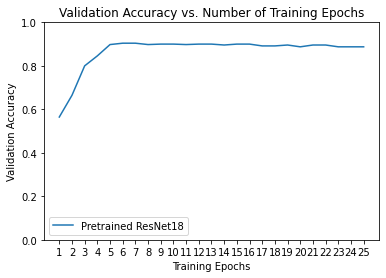

In [ ]:
# Plot the training curves of validation accuracy vs. number
#  of training epochs for the transfer learning method and
#  the model trained from scratch
ohist = []
shist = []

ohist = [h.cpu().numpy() for h in hist]

plt.title("Validation Accuracy vs. Number of Training Epochs")
plt.xlabel("Training Epochs")
plt.ylabel("Validation Accuracy")
plt.plot(range(1,num_epochs+1),ohist,label="Pretrained ResNet18 with 3,5k images")
plt.ylim((0,1.))
plt.xticks(np.arange(1, num_epochs+1, 1.0))
plt.legend()
plt.show()